In [1]:

%pip install torch torchvision pydicom pylibjpeg pylibjpeg-openjpeg pandas numpy matplotlib scikit-learn


  Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.3/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.5/124.1 MB 1.1 MB/s eta 0:01:56
   ---------------------------------------- 0.8/124.1 MB 1.4 MB/s eta 0:01:27
   ---------------------------------------- 1.0/124.1 MB 1.3 MB/s eta 0:01:35
    --------------------------------------- 1.6/124.1 MB 1.5 MB/s eta 0:01:23
    --------------------------------------- 1.8/124.1 MB 1.5 MB/s eta 0:


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:

from pathlib import Path
import numpy as np
import pandas as pd
import pydicom
import torch
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "data" / "processed").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Project root not found")
    ROOT = ROOT.parent

manifest = pd.read_csv(
    ROOT / "data/processed/validated_manifest.csv",
    dtype={"image_id": str}
)
annotations = pd.read_csv(
    ROOT / "data/annotations/annotations_train.csv",
    dtype={"image_id": str}
)

SIZE = 256

def load_image_and_mask(row):
    path = ROOT / row["dicom_path"]
    ds = pydicom.dcmread(str(path))
    image = ds.pixel_array.astype(np.float32)

    # Normalize image
    image -= image.min()
    if image.max() > 0:
        image /= image.max()

    h, w = image.shape

    image = torch.nn.functional.interpolate(
        torch.tensor(image)[None, None],
        size=(SIZE, SIZE),
        mode="bilinear",
        align_corners=False
    )[0, 0].numpy()

    mask = np.zeros((SIZE, SIZE), dtype=np.float32)

    boxes = annotations[
        annotations["image_id"] == str(row["image_id"])
    ].dropna(subset=["x_min", "y_min", "x_max", "y_max"])

    for _, b in boxes.iterrows():
        x1 = int(np.clip(b["x_min"] / w * SIZE, 0, SIZE - 1))
        x2 = int(np.clip(b["x_max"] / w * SIZE, 0, SIZE))
        y1 = int(np.clip(b["y_min"] / h * SIZE, 0, SIZE - 1))
        y2 = int(np.clip(b["y_max"] / h * SIZE, 0, SIZE))
        mask[y1:y2, x1:x2] = 1.0

    return image, mask

# Use every validated image that has bounding boxes
sample = manifest[manifest["has_bbox"]].reset_index(drop=True)

images, masks = [], []
failed_ids = []

for _, row in sample.iterrows():
    try:
        image, mask = load_image_and_mask(row)
        images.append(image)
        masks.append(mask)
    except Exception as e:
        failed_ids.append((row["image_id"], str(e)))

images = np.stack(images)
masks = np.stack(masks)

print("Images loaded:", len(images))
print("Image array:", images.shape)
print("Pseudo-mask array:", masks.shape)
print("Positive mask proportion:", float(masks.mean()))
print("Failed images:", len(failed_ids))
if failed_ids:
    print(failed_ids)


Images loaded: 100
Image array: (100, 256, 256)
Pseudo-mask array: (100, 256, 256)
Positive mask proportion: 0.11935851722955704
Failed images: 0


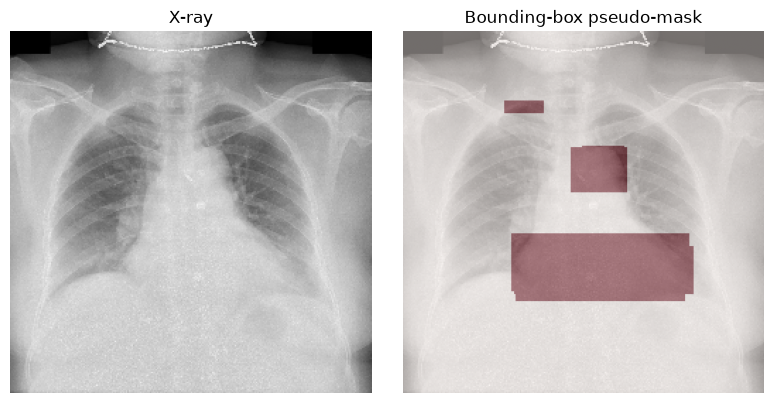

In [3]:

i = 0

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(images[i], cmap="gray")
ax[0].set_title("X-ray")
ax[0].axis("off")

ax[1].imshow(images[i], cmap="gray")
ax[1].imshow(masks[i], cmap="Reds", alpha=0.45)
ax[1].set_title("Bounding-box pseudo-mask")
ax[1].axis("off")

plt.tight_layout()
plt.show()


In [4]:

from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader
import torch

X = torch.tensor(images[:, None], dtype=torch.float32)
Y = torch.tensor(masks[:, None], dtype=torch.float32)

train_idx, val_idx = train_test_split(
    np.arange(len(X)),
    test_size=0.2,
    random_state=42,
)

train_ds = TensorDataset(X[train_idx], Y[train_idx])
val_ds = TensorDataset(X[val_idx], Y[val_idx])

train_loader = DataLoader(train_ds, batch_size=4, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=4, shuffle=False)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Train images:", len(train_ds))
print("Validation images:", len(val_ds))


Device: cpu
Train images: 16
Validation images: 4


In [5]:

import torch.nn as nn

def block(in_ch, out_ch):
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, 3, padding=1),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_ch, out_ch, 3, padding=1),
        nn.ReLU(inplace=True),
    )

class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1 = block(1, 16)
        self.enc2 = block(16, 32)
        self.enc3 = block(32, 64)
        self.pool = nn.MaxPool2d(2)

        self.bottleneck = block(64, 128)

        self.up3 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec3 = block(128, 64)
        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec2 = block(64, 32)
        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.dec1 = block(32, 16)

        self.out = nn.Conv2d(16, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        b = self.bottleneck(self.pool(e3))

        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.out(d1)

model = UNet().to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))


Trainable parameters: 481745


In [12]:

import torch
import torch.nn as nn

bce = nn.BCEWithLogitsLoss()

def dice_loss(logits, targets, smooth=1.0):
    probs = torch.sigmoid(logits)
    probs = probs.flatten(start_dim=1)
    targets = targets.flatten(start_dim=1)

    intersection = (probs * targets).sum(dim=1)
    denominator = probs.sum(dim=1) + targets.sum(dim=1)

    dice = (2 * intersection + smooth) / (denominator + smooth)
    return 1 - dice.mean()

def combined_loss(logits, targets):
    return bce(logits, targets) + dice_loss(logits, targets)

criterion = combined_loss
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)


In [13]:

EPOCHS = 5

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * xb.size(0)

    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            val_loss += criterion(model(xb), yb).item() * xb.size(0)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train loss: {train_loss / len(train_ds):.4f} | "
        f"Val loss: {val_loss / len(val_ds):.4f}"
    )


Epoch 1/5 | Train loss: 1.3830 | Val loss: 1.3373
Epoch 2/5 | Train loss: 1.3689 | Val loss: 1.3502
Epoch 3/5 | Train loss: 1.3669 | Val loss: 1.3290
Epoch 4/5 | Train loss: 1.3481 | Val loss: 1.2956
Epoch 5/5 | Train loss: 1.3057 | Val loss: 1.2830


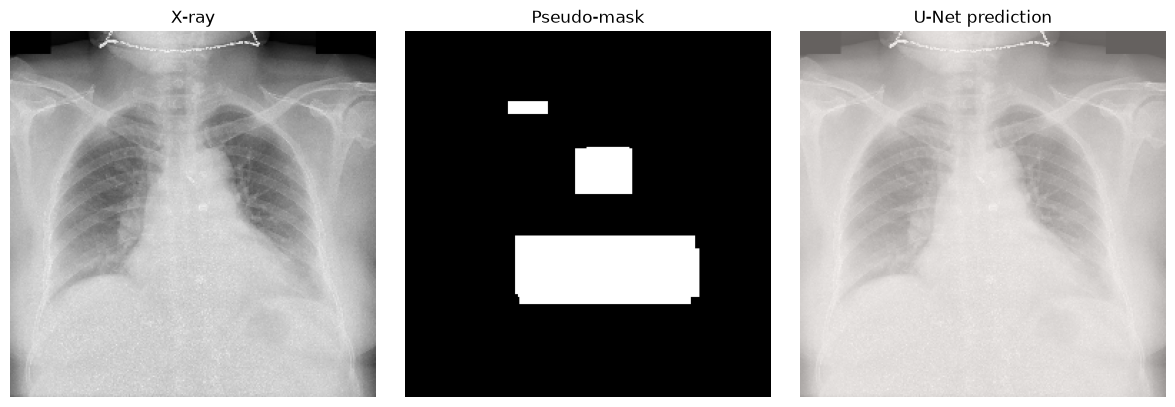

In [7]:

model.eval()

with torch.no_grad():
    sample_x, sample_y = next(iter(val_loader))
    pred = torch.sigmoid(model(sample_x.to(device)))[0, 0].cpu().numpy()

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(sample_x[0, 0], cmap="gray")
ax[0].set_title("X-ray")
ax[1].imshow(sample_y[0, 0], cmap="gray")
ax[1].set_title("Pseudo-mask")
ax[2].imshow(sample_x[0, 0], cmap="gray")
ax[2].imshow(pred >= 0.5, cmap="Reds", alpha=0.4)
ax[2].set_title("U-Net prediction")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


Probability min: 0.15555315
Probability max: 0.47506443
Probability mean: 0.21354024
Pixels predicted positive at 0.5: 0
Positive target pixels: 7678


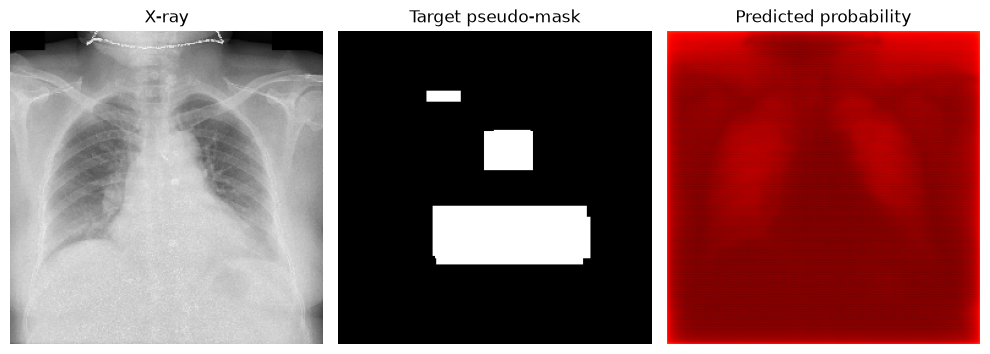

In [8]:

model.eval()

with torch.no_grad():
    xb, yb = next(iter(val_loader))
    probabilities = torch.sigmoid(model(xb.to(device))).cpu()

p = probabilities[0, 0].numpy()
target = yb[0, 0].numpy()

print("Probability min:", p.min())
print("Probability max:", p.max())
print("Probability mean:", p.mean())
print("Pixels predicted positive at 0.5:", (p >= 0.5).sum())
print("Positive target pixels:", (target >= 0.5).sum())

fig, ax = plt.subplots(1, 3, figsize=(10, 4))
ax[0].imshow(xb[0, 0], cmap="gray")
ax[0].set_title("X-ray")
ax[1].imshow(target, cmap="gray", vmin=0, vmax=1)
ax[1].set_title("Target pseudo-mask")
ax[2].imshow(p, cmap="hot", vmin=0, vmax=1)
ax[2].set_title("Predicted probability")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()


In [9]:

print("Probability min:", float(p.min()))
print("Probability max:", float(p.max()))
print("Probability mean:", float(p.mean()))
print("Pixels >= 0.5:", int((p >= 0.5).sum()))
print("Target positive pixels:", int((target >= 0.5).sum()))
print("Target positive fraction:", float(target.mean()))


Probability min: 0.15555314719676971
Probability max: 0.4750644266605377
Probability mean: 0.2135402411222458
Pixels >= 0.5: 0
Target positive pixels: 7678
Target positive fraction: 0.117156982421875


Threshold: 0.25
Predicted positive fraction: 0.1538238525390625
Target positive fraction: 0.11715698


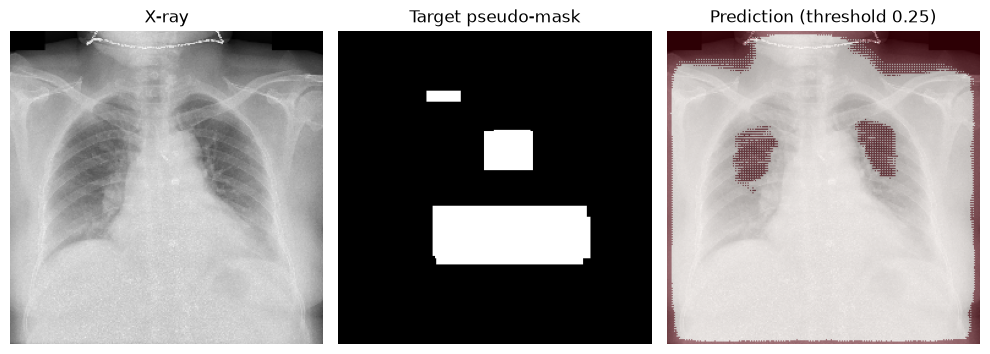

In [10]:

threshold = 0.25
pred_mask = (p >= threshold).astype("uint8")

print("Threshold:", threshold)
print("Predicted positive fraction:", pred_mask.mean())
print("Target positive fraction:", target.mean())

fig, ax = plt.subplots(1, 3, figsize=(10, 4))
ax[0].imshow(xb[0, 0], cmap="gray")
ax[0].set_title("X-ray")

ax[1].imshow(target, cmap="gray")
ax[1].set_title("Target pseudo-mask")

ax[2].imshow(xb[0, 0], cmap="gray")
ax[2].imshow(pred_mask, cmap="Reds", alpha=0.45)
ax[2].set_title("Prediction (threshold 0.25)")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


Mean probability: 0.17430879175662994
Predicted positive fraction: 0.0
Target positive fraction: 0.117156982421875


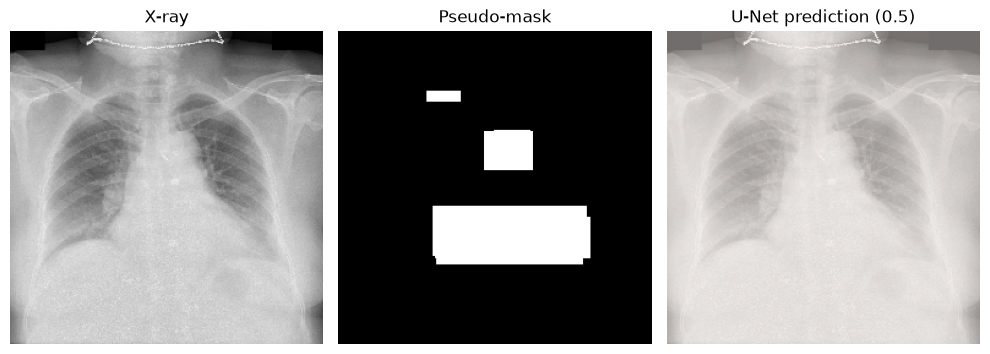

In [14]:

model.eval()

with torch.no_grad():
    xb, yb = next(iter(val_loader))
    probabilities = torch.sigmoid(model(xb.to(device))).cpu()

p = probabilities[0, 0].numpy()
target = yb[0, 0].numpy()
pred_mask = (p >= 0.5).astype("uint8")

print("Mean probability:", float(p.mean()))
print("Predicted positive fraction:", float(pred_mask.mean()))
print("Target positive fraction:", float(target.mean()))

fig, ax = plt.subplots(1, 3, figsize=(10, 4))
ax[0].imshow(xb[0, 0], cmap="gray")
ax[0].set_title("X-ray")
ax[1].imshow(target, cmap="gray")
ax[1].set_title("Pseudo-mask")
ax[2].imshow(xb[0, 0], cmap="gray")
ax[2].imshow(pred_mask, cmap="Reds", alpha=0.45)
ax[2].set_title("U-Net prediction (0.5)")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()
